# Image Denoising with $K$-Nearest Neighbors: From MNIST to PneumoniaMNIST

## Overview
Welcome to this companion Jupyter Notebook for the article **"The Power of Classification: A Hands-on Guide to Image Denoising Using Simple ML Algorithms"**. 

This notebook provides a complete, reproducible implementation of an image denoising workflow using $K$-Nearest Neighbors ($K$-NN). To evaluate the algorithm across different complexity levels and domains, the notebook executes the denoising pipeline across two distinct datasets:

1. **Standard Digit Benchmark:** Denoising handwritten digits using the classic **MNIST** dataset.
2. **Medical Imaging Application:** Applying the same approach to pediatric chest X-ray scans using the **PneumoniaMNIST** dataset.

All code, data pipelines, trained outputs, and visual comparative results are presented below.

---

## Objective & Methodology

In digital imaging, noise can degrade visual quality during acquisition or transmission. In this notebook, we set up a multi-output learning task where **noisy pixel arrays** act as input features ($X$) and **clean original images** serve as target outputs ($y$).

### Stage 1: Standard MNIST Denoising
* **Data Processing:** Fetching 70,000 $28 \times 28$ pixel grayscale handwritten digits and splitting them into training and testing sets.
* **Noise Generation:** Adding uniform random synthetic noise to pixel arrays using NumPy.
* **Model Fitting:** Training a $K$-NN model for multi-output pixel reconstruction and evaluating visual clarity on restored digits.

### Stage 2: PneumoniaMNIST Denoising
* **Medical Domain Adaptation:** Loading grayscale pediatric chest X-ray images via the `medmnist` library.
* **Noise Injection & Denoising:** Subjecting chest X-rays to artificial pixel degradation, re-applying the multi-output $K$-NN regressor, and analyzing how non-parametric restoration performs on low-contrast medical imaging structures.

---

> **Repo & Article References:**
> - **Article:** [Hashnode](https://hashnode.com/@alrza)
> - **GitHub Repository:** [GitHub](https://github.com/AlrzA2003/Notebooks)
> - **Environment:** Python 3.x | `scikit-learn` | `numpy` | `matplotlib` | `medmnist`

## Setup

To get the most out of this notebook, you should have a foundational understanding of: **Python,** **NumPy,** **Pandas,** **Scikit-learn,**

---

### Installation
Ensure all required dependencies are installed in your Python environment before running the notebook cells:

```bash
pip install numpy pandas matplotlib scikit-learn medmnist

This project requires Python 3.10 or above, as well as Scikit-Learn ≥ 1.6.1:

In [1]:
import sys
import sklearn
print(f"Python version: {sys.version.split(" |")[0]}\nScikit-Learn version: {sklearn.__version__}")

Python version: 3.14.7
Scikit-Learn version: 1.9.1


## 1st Stage: KNN Performance on MNIST Dataset
We start with loading MNIST dataset into our notebook:

In [2]:
from sklearn.datasets import fetch_openml
mnist = fetch_openml('mnist_784', as_frame=False)

In [3]:
print(mnist.DESCR)

**Author**: Yann LeCun, Corinna Cortes, Christopher J.C. Burges  
**Source**: [MNIST Website](http://yann.lecun.com/exdb/mnist/) - Date unknown  
**Please cite**:  

The MNIST database of handwritten digits with 784 features, raw data available at: http://yann.lecun.com/exdb/mnist/. It can be split in a training set of the first 60,000 examples, and a test set of 10,000 examples  

It is a subset of a larger set available from NIST. The digits have been size-normalized and centered in a fixed-size image. It is a good database for people who want to try learning techniques and pattern recognition methods on real-world data while spending minimal efforts on preprocessing and formatting. The original black and white (bilevel) images from NIST were size normalized to fit in a 20x20 pixel box while preserving their aspect ratio. The resulting images contain grey levels as a result of the anti-aliasing technique used by the normalization algorithm. the images were centered in a 28x28 image b

Because we are only interested in denoising the dataset, we just import the mnist.data:<br>
(The labels for mnist is available under mnist.target)

In [4]:
X = mnist.data
X.shape

(70000, 784)

Now, We define a function to simply plot our pictures:

In [5]:
# Define a function to plot the pictures:
import matplotlib.pyplot as plt

def plot_mnist_image(image_data):
    plt.figure(figsize=(2, 2))
    image = image_data.reshape(28, 28)
    plt.imshow(image, cmap="binary")
    plt.axis("off")
    plt.show()

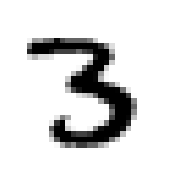

In [6]:
plot_mnist_image(X[12])

It's time to split our data into train and test sets:

In [7]:
mnist_train, mnist_test = X[:60000], X[60000:]

Here, We use default_rng() method to produce artificial noise in our pictures:

In [8]:
import numpy as np

rng_mnist = np.random.default_rng(seed=42)

In [9]:
train_noises = rng_mnist.integers(0, 100, mnist_train.shape)
test_noises = rng_mnist.integers(0, 100, mnist_test.shape)
X_train = mnist_train + train_noises
X_test = mnist_test + test_noises
y_train = mnist_train
y_test = mnist_test

Let's look at the noisy picture, as well as the clean one:

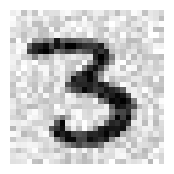

In [10]:
plot_mnist_image(X_train[12])

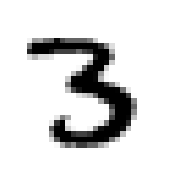

In [11]:
plot_mnist_image(y_train[12])

Here the main part starts: using KNN to DENOISE our images:

In [12]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier()

In [13]:
knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier",list,"[array([0]), array([0]), array([0]), array([0]), ...]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [14]:
# Now we take a look at one sample from our test set:
pred = knn.predict([X_test[9]])

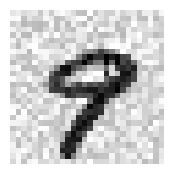

In [15]:
plot_mnist_image(X_test[9])

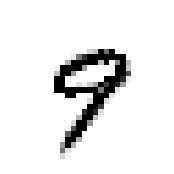

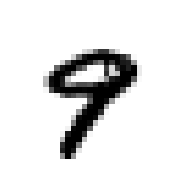

In [16]:
# Prediction (Denoised picture) Vs. Actual clean picture comparison
plot_mnist_image(pred)
plot_mnist_image(y_test[9])

#### The result is not too bad, Right? 

## Stage 2: KNN Performance on PneumoniaMNIST Dataset

### What is PneumoniaMNIST?
[Pneumonia](https://my.clevelandclinic.org/health/diseases/4471-pneumonia) is an inflammatory lung infection that causes the air sacs (alveoli) to fill with fluid or pus. The **PneumoniaMNIST** dataset (part of the MedMNIST collection) consists of normalized $28 \times 28$ grayscale chest X-ray images labeled as either normal or pneumonia, serving as a lightweight benchmark for medical image processing.

---

### Dataset Acquisition

You can acquire the dataset using either of the following methods:
* **Direct Download:** Fetch the dataset directly from [Kaggle](https://www.kaggle.com/datasets/rijulshr/pneumoniamnist).
* **Automated Download (`kagglehub`):** Install via `pip install kagglehub` and fetch the files directly using `kagglehub.dataset_download("rijulshr/pneumoniamnist")`.

In [17]:
import kagglehub

# Download latest version of chest CT-Scan images:
path = kagglehub.dataset_download(
    "rijulshr/pneumoniamnist", output_dir="pneumonia",
    force_download=True
)

print("Path to dataset files:", path)

100%|██████████| 3.39M/3.39M [00:14<00:00, 247kB/s]

Extracting files...
Path to dataset files: pneumonia


In [18]:
# Load the dataset
from pathlib import Path
data = np.load(Path("pneumonia/pneumoniamnist.npz"))

#### The rest is almost the same as the MNIST dataset:

In [19]:
train_pneumoniamnist, test_pneumoniamnist = data["train_images"], data["test_images"]

In [20]:
train_pneumoniamnist.shape

(3882, 28, 28)

In [21]:
test_pneumoniamnist.shape

(624, 28, 28)

In [22]:
# Define a function to plot the pictures:

def plot_pneumoniamnist_image(image_data):
    plt.figure(figsize=(3, 3))
    plt.imshow(image_data, cmap="binary")
    plt.axis("off")
    plt.show()

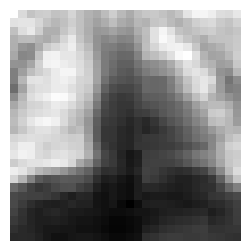

In [23]:
plot_pneumoniamnist_image(train_pneumoniamnist[17])

In [24]:
rng_pneumoniamnist = np.random.default_rng(seed=42)

Note that we have to reshape our image data from a 3D array into a 2D array: (KNN cannot operate with a 3D array)

In [25]:
pneumoniamnist_train_noises = rng_pneumoniamnist.integers(
    0, 100, size=train_pneumoniamnist.shape
)
pneumoniamnist_test_noises = rng_pneumoniamnist.integers(
    0, 100, size=test_pneumoniamnist.shape
)
X_train_pneumonia = (train_pneumoniamnist + pneumoniamnist_train_noises).reshape(
    len(train_pneumoniamnist), 784
)
X_test_pneumonia = (test_pneumoniamnist + pneumoniamnist_test_noises).reshape(
    len(test_pneumoniamnist), 784
)
y_train_pneumonia = train_pneumoniamnist.reshape(len(train_pneumoniamnist), 784)
y_test_pneumonia = test_pneumoniamnist.reshape(len(test_pneumoniamnist), 784)

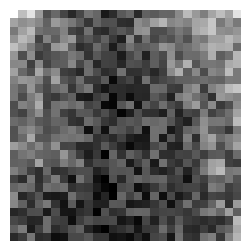

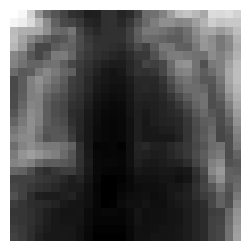

In [26]:
# Noisy image with clean image comparison:
plot_pneumoniamnist_image(X_test_pneumonia[4].reshape(28, 28))
plot_pneumoniamnist_image(y_test_pneumonia[4].reshape(28, 28))

In [27]:
knn_pneumonia = KNeighborsClassifier()

In [28]:
knn_pneumonia.fit(X_train_pneumonia, y_train_pneumonia)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier",list,"[array([ 0, ... dtype=uint8), array([ 0, ..., dtype=uint8), array([ 0, ..., dtype=uint8), array([ 0, ..., dtype=uint8), ...]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [29]:
pred_pneumonia = knn_pneumonia.predict([X_test_pneumonia[4]])

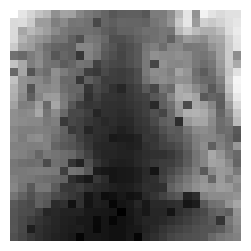

In [30]:
plot_pneumoniamnist_image(pred_pneumonia.reshape(28, 28))

## Conclusion

The main goal of this notebook was to demonstrate that essential image preprocessing and denoising can be effectively handled using simple Machine Learning algorithms like $K$-Nearest Neighbors ($K$-NN), without immediately resorting to complex deep learning architectures.

While basic algorithms perform remarkably well on clean, high-contrast images like **MNIST** with well-defined edges, lower-contrast medical images like **PneumoniaMNIST** present more of a challenge due to subtle pixel gradations. Nevertheless, leveraging classic ML techniques for multi-output reconstruction provides a simple, intuitive, and appropriate baseline for image restoration.

Hope you enjoyed exploring this notebook!